ACTIVITY 1

In [1]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Activity 1.1: Data Preparation
X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_and = np.array([0, 0, 0, 1])

# Activity 1.2: Initialize weights and bias
np.random.seed(42)
weights = np.random.rand(2) * 0.1
bias = np.random.rand(1)[0] * 0.1

# Step function
def step_function(z):
    return 1 if z >= 0 else 0

# Learning parameters
learning_rate = 0.1
epochs = 20

# Train the Perceptron
for epoch in range(epochs):
    for x, y_true in zip(X_and, y_and):
        z = np.dot(x, weights) + bias
        prediction = step_function(z)
        error = y_true - prediction

        weights = weights + learning_rate * error * x
        bias = bias + learning_rate * error

# Make predictions
y_pred = np.array([
    step_function(np.dot(x, weights) + bias)
    for x in X_and
])

# Display results
print("AND Gate Predictions:")
for x, prediction in zip(X_and, y_pred):
    print(f"{x} = {prediction}")

# Calculate accuracy
accuracy = accuracy_score(y_and, y_pred)
print("Actual Output:", y_and)
print("Predicted Output:", y_pred)
print("Accuracy:", accuracy)

AND Gate Predictions:
[0 0] = 0
[0 1] = 0
[1 0] = 0
[1 1] = 1
Actual Output: [0 0 0 1]
Predicted Output: [0 0 0 1]
Accuracy: 1.0


ACTIVITY 2

In [2]:
import numpy as np
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Step 1: Create shape data
# Features: Number of corners, Aspect ratio
# 0 = Square, 1 = Circle

X_shapes = np.array([
    [4, 1.0],
    [4, 1.05],
    [4, 0.95],
    [0, 1.0],
    [0, 1.1],
    [0, 0.9],
    [4, 0.5],
    [0, 2.0]
])

# Target labels
y_shapes = np.array([0, 0, 0, 1, 1, 1, 0, 1])

# Step 2: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_shapes, y_shapes,
    test_size=0.3,
    random_state=42
)

print("Training Data:")
print(X_train)

print("Training Labels:")
print(y_train)

# Step 3: Create the MLP classifier
model = MLPClassifier(
    hidden_layer_sizes=(5,),
    max_iter=500,
    random_state=42,
    solver='adam'
)

# Step 4: Train the model
model.fit(X_train, y_train)

# Step 5: Predict the test data
y_pred = model.predict(X_test)

print("Actual Labels:", y_test)
print("Predicted Labels:", y_pred)

# Step 6: Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Training Data:
[[0.   2.  ]
 [4.   0.95]
 [0.   1.1 ]
 [0.   1.  ]
 [4.   0.5 ]]
Training Labels:
[1 0 1 1 0]
Actual Labels: [0 1 0]
Predicted Labels: [0 1 0]
Accuracy: 1.0


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Backpropagation is an algorithm used to train a neural network. First, the network makes a prediction. The prediction is compared with the actual answer to calculate the error. Then, the error is passed backward through the network to determine how the weights contributed to the mistake. The weights are adjusted to reduce the error. By repeating this process during training, the network gradually learns to make better predictions.

In simple words: Backpropagation helps the neural network learn from its mistakes by sending the error backward and adjusting its weights.

ACTIVITY 3

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9263 - loss: 0.2616
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9658 - loss: 0.1170
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9750 - loss: 0.0813
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9816 - loss: 0.0594
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9865 - loss: 0.0454
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9750 - loss: 0.0813
Test Accuracy: 0.9750000238418579
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
Predicted Digit: 7
Actual Digit: 7


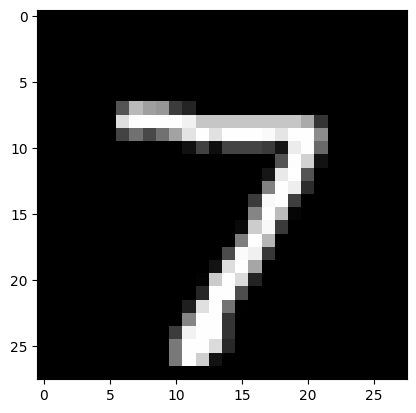

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Step 1: Load the MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Step 2: Normalize the images
X_train = X_train / 255.0
X_test = X_test / 255.0

# Step 3: Create the neural network
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Step 4: Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 5: Train the model
model.fit(X_train, y_train, epochs=5)

# Step 6: Test the model
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

# Step 7: Predict a digit
prediction = model.predict(X_test[:1])
print("Predicted Digit:", prediction.argmax())
print("Actual Digit:", y_test[0])

# Display the test image
plt.imshow(X_test[0], cmap='gray')
plt.show()

ACTIVITY 4

In [4]:
import time
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

# Step 1: Load dataset
X, y = load_breast_cancer(return_X_y=True)

# Step 2: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Step 3: Scale the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 4: Compare activation functions
functions = ['logistic', 'tanh', 'relu']

for func in functions:
    model = MLPClassifier(
        hidden_layer_sizes=(50,),
        activation=func,
        max_iter=500,
        random_state=42,
        solver='adam'
    )

    # Measure training time
    start = time.time()
    model.fit(X_train, y_train)
    end = time.time()

    # Predict test data
    y_pred = model.predict(X_test)

    # Calculate accuracy
    accuracy = accuracy_score(y_test, y_pred)

    print("\nActivation Function:", func)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Training Time:", round(end - start, 3), "seconds")
    print("Iterations:", model.n_iter_)


Activation Function: logistic
Accuracy: 95.61 %
Training Time: 1.723 seconds
Iterations: 260

Activation Function: tanh
Accuracy: 97.37 %
Training Time: 2.468 seconds
Iterations: 399

Activation Function: relu
Accuracy: 95.61 %
Training Time: 1.138 seconds
Iterations: 302



Activation

What to check

Sigmoid (logistic)

Accuracy and whether training takes more iterations

Tanh

Accuracy and convergence compared with Sigmoid

ReLU

Whether it achieves good accuracy in less time

Accuracy: Higher accuracy means more test examples were classified correctly.

Training time: Lower time means the model trained faster on your computer.

Iterations: Fewer iterations to convergence can indicate faster learning, although iterations are not a perfect measure of speed.

The Sigmoid, Tanh, and ReLU activation functions were compared using the same dataset and neural network structure. Their performance was evaluated using classification accuracy, training time, and number of iterations. ReLU often converges faster and performs well in hidden layers, while Sigmoid and Tanh can experience vanishing gradients. The best-performing function depends on the dataset and training conditions.